# 01 – Exploring the Citi Bike trip data

The raw-data checks use one month (August 2026). From *Cleaning result* onwards, the cells use the full cleaned study year (Sep 2025 – Aug 2026). Together they motivate the rules in `citibike.clean`.

**Prerequisites** (run from the project root with `.venv` active):
```bash
python -m citibike.download 2025-09 2026-08
python -m citibike.convert
python -m citibike.clean
python -m citibike.features
```

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from citibike.paths import PARQUET, PROCESSED

con = duckdb.connect()
con.execute(f"CREATE VIEW raw AS SELECT *, epoch(ended_at - started_at) AS dur FROM '{PARQUET}/trips/month=202608/*.parquet'")
con.execute('''CREATE VIEW raw_ends AS
    SELECT start_station_id AS id, start_station_name AS name, start_lat AS lat, start_lng AS lng FROM raw
    UNION ALL SELECT end_station_id, end_station_name, end_lat, end_lng FROM raw''')
q = lambda sql: con.sql(sql).df()

## Schema, size and time range
The zip for a month holds the trips that *end* in that month, so a few start on the last day of the previous month.

In [2]:
q("DESCRIBE raw")

,column_name,column_type,null,key,default,extra
0,ride_id,VARCHAR,YES,None,None,None
1,rideable_type,VARCHAR,YES,None,None,None
2,started_at,TIMESTAMP,YES,None,None,None
3,ended_at,TIMESTAMP,YES,None,None,None
4,start_station_name,VARCHAR,YES,None,None,None
5,start_station_id,VARCHAR,YES,None,None,None
6,end_station_name,VARCHAR,YES,None,None,None
7,end_station_id,VARCHAR,YES,None,None,None
8,start_lat,DOUBLE,YES,None,None,None
9,start_lng,DOUBLE,YES,None,None,None


In [3]:
q("SELECT count(*) AS trips, count(DISTINCT ride_id) AS unique_ride_ids, min(started_at), max(started_at), min(ended_at), max(ended_at) FROM raw")

,trips,unique_ride_ids,min(started_at),max(started_at),min(ended_at),max(ended_at)
0,5246236,5246236,2026-07-31 02:10:56.632,2026-08-31 23:58:01.765,2026-08-01 00:00:00.865,2026-08-31 23:59:59.524


## Missing values
Missing stations are mostly e-bikes that were left outside a dock.

In [4]:
q('''SELECT rideable_type, count(*) AS trips,
       round(100 * avg((start_station_id IS NULL)::INT), 3) AS pct_no_start,
       round(100 * avg((end_station_id IS NULL)::INT), 3) AS pct_no_end,
       round(100 * avg((end_lat IS NULL)::INT), 3) AS pct_no_end_coords
FROM raw GROUP BY 1''')

,rideable_type,trips,pct_no_start,pct_no_end,pct_no_end_coords
0,electric_bike,3832654,0.075,0.352,0.352
1,classic_bike,1413582,0.000,0.091,0.088


## Trip durations
The operator already removed trips under 60 s. A long tail of trips lasting hours or days is most likely bikes that were not docked properly.

                                   minutes_quantiles  over_3h
0  [1.0000833333333334, 1.5257391666666666, 9.786...   6020.0


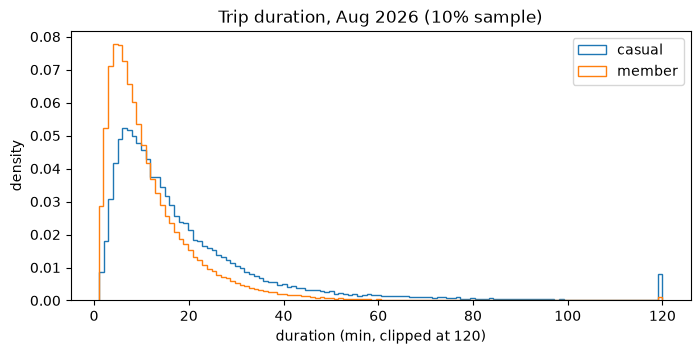

In [5]:
d = q("SELECT dur / 60 AS minutes, member_casual FROM raw USING SAMPLE 10%")
print(q("SELECT quantile_cont(dur/60, [0, .01, .5, .99, .999, 1]) AS minutes_quantiles, sum((dur > 3*3600)::INT) AS over_3h FROM raw"))
fig, ax = plt.subplots(figsize=(8, 3.5))
for g, sub in d.groupby("member_casual"):
    ax.hist(sub.minutes.clip(upper=120), bins=120, histtype="step", density=True, label=g)
ax.set(xlabel="duration (min, clipped at 120)", ylabel="density", title="Trip duration, Aug 2026 (10% sample)")
ax.legend();

## Station identifiers
The IDs are strings like `5980.10`, but the source sometimes drops the trailing zero or adds a `_`, so one physical station can appear under two IDs.

In [6]:
q('''SELECT name, list(DISTINCT id ORDER BY id) AS ids, count(*) AS trip_ends
FROM raw_ends WHERE id IS NOT NULL GROUP BY name HAVING count(DISTINCT id) > 1 ORDER BY trip_ends DESC LIMIT 8''')

,name,ids,trip_ends
0,E 17 St & Broadway,"[5980.1, 5980.10]",32199
1,Broadway & E 21 St,"[6098.1, 6098.10]",23628
2,N 6 St & Bedford Ave,"[5379.1, 5379.10]",22371
3,Clinton St & Grand St,"[5303.06, 5303.06_]",22141
4,Lafayette St & Astor Pl,"[5712.1, 5712.10]",21971
5,6 Ave & W 34 St,"[6364.1, 6364.10]",17434
6,E 2 St & Ave A,"[5553.1, 5553.10]",15893
7,St Marks Pl & 2 Ave,"[5669.1, 5669.10]",15301


IDs that aren't numeric belong to Jersey City (`JC*`), Hoboken (`HB*`), or operator/maintenance locations (`SYS*`, `Shop Morgan`). One more operator facility, **"Morgan HCT Charging"**, uses the normal-looking id `1234.56` and turned up in the graph analysis, so `clean.py` also drops stations whose name matches charging/depot/warehouse/loading dock/mechanic:

In [7]:
q('''SELECT regexp_extract(id, '^[A-Za-z ]+') AS prefix, count(DISTINCT id) AS stations, count(*) AS trip_ends, any_value(name) AS example
FROM raw_ends WHERE NOT regexp_matches(id, '^\\d+\\.\\d+_?$') GROUP BY 1 ORDER BY trip_ends DESC''')

,prefix,stations,trip_ends,example
0,SYS,3,915,Morgan Bike Mechanics
1,JC,29,171,Arlington Ave & Wilkinson Ave
2,HB,22,156,Bloomfield St & 15 St
3,Shop Morgan,1,33,Shop Morgan


The coordinates are the station's own position, not GPS, even for e-bikes. There's about one distinct coordinate pair per station:

In [8]:
q("SELECT avg(n) AS distinct_coords_per_station FROM (SELECT id, count(DISTINCT (lat, lng)) AS n FROM raw_ends WHERE id IS NOT NULL GROUP BY id)")

,distinct_coords_per_station
0,1.0


## Cleaning result (full year)
Each trip is dropped for at most one reason (the first rule that matches), so the numbers add up to the raw count. Two problems only show up across the full year. The April and May zips overlap at the month boundary (duplicate ride IDs). Trips during the 2025-11-02 daylight-saving change get negative durations, because timestamps have no time zone. Six stations were renumbered without moving and are merged (see below).

In [9]:
pd.read_csv(PROCESSED / "cleaning_report.csv")

,outcome,trips,pct
0,kept,45488697,99.562
1,missing station,153577,0.336
2,too long,30180,0.066
3,non-NYC or operator station,14346,0.031
4,outside study window,931,0.002
5,negative duration (DST),482,0.001
6,duplicate ride_id,465,0.001
7,implausible speed,18,0.000
8,too short,1,0.000


In [10]:
pd.read_csv(PROCESSED / "station_aliases.csv")

,old_id,new_id,name
0,6441.01,6441.11,Broadway & W 36 St
1,7625.18,7625.22,E 118 St & Park Ave
2,5073.07,5073.08,Greenwich St & Rector St
3,5561.06,5561.08,Lafayette St & Jersey St
4,4101.17,4101.18,President St & 4 Ave
5,8381.04,8421.03,W 181 St & Riverside Dr


## Temporal pattern
Weekdays show the commuter double peak. Weekends have a single midday peak.

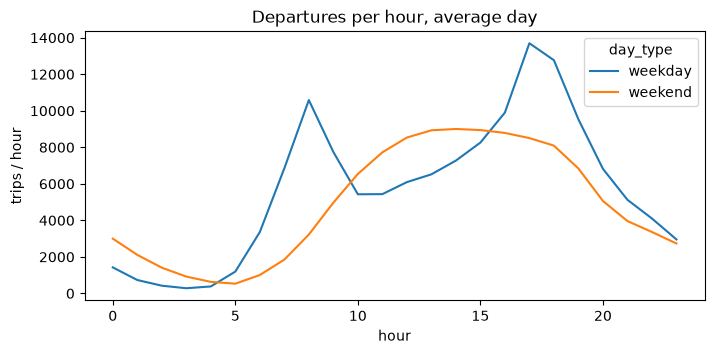

In [11]:
prof = pd.read_parquet(PROCESSED / "profiles.parquet")
hourly = prof.groupby(["day_type", "hour"]).departures.sum().unstack(0)
ax = hourly.plot(figsize=(8, 3.5), title="Departures per hour, average day")
ax.set(ylabel="trips / hour");

## Morning net flow
Weekday 7–10 am: red stations fill up (sinks, e.g. job centres) and blue stations empty (sources, residential areas). This is the signal the profile clustering should recover.

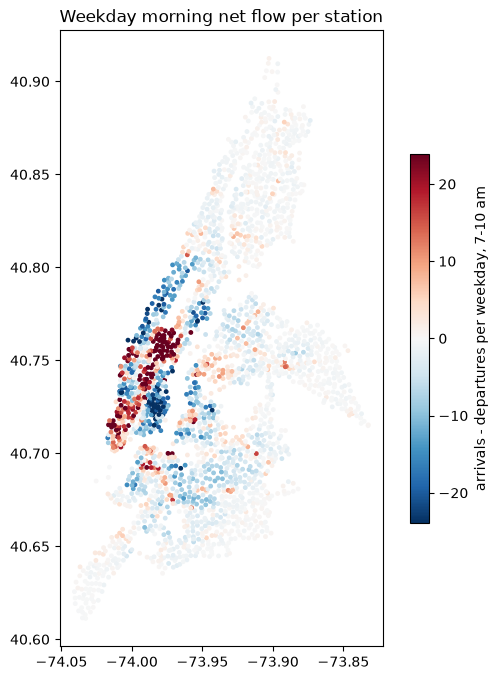

In [12]:
st = pd.read_parquet(PROCESSED / "stations.parquet")
am = prof.query("day_type == 'weekday' and 7 <= hour <= 9").groupby("station_id").net.sum().rename("am_net")
m = st.join(am, on="station_id")
lim = m.am_net.abs().quantile(0.95)
fig, ax = plt.subplots(figsize=(7, 8))
sc = ax.scatter(m.lng, m.lat, c=m.am_net.clip(-lim, lim), cmap="RdBu_r", s=6)
ax.set_aspect(1 / 0.758)  # cos(40.7 deg)
fig.colorbar(sc, label="arrivals - departures per weekday, 7-10 am", shrink=0.6)
ax.set_title("Weekday morning net flow per station");

In [13]:
m.sort_values("am_net")[["name", "am_net"]].iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]]

,name,am_net
1589,W 43 St & 10 Ave,-57.634538
1038,E 10 St & Ave A,-44.349398
1009,E 6 St & Ave B,-42.570281
1754,Riverside Blvd & W 67 St,-42.378151
975,E 2 St & Ave B,-41.630522
671,Dock 72 Way & Market St,60.341365
1263,Broadway & W 25 St,64.084337
951,Greenwich St & Hubert St,66.449799
1497,E 47 St & Park Ave,75.040161
1444,9 Ave & W 33 St,104.337349


## Graph size per time slice

In [14]:
q(f"SELECT slice, count(*) AS edges, count(DISTINCT src) AS nodes, sum(trips) AS trips FROM '{PROCESSED}/edges.parquet' GROUP BY 1 ORDER BY 1")

,slice,edges,nodes,trips
0,all,1612910,2384,44567641.0
1,weekday_am,576864,2374,6782275.0
2,weekday_midday,876701,2381,9137854.0
3,weekday_night,771825,2381,5448355.0
4,weekday_pm,950229,2380,10762516.0
5,weekend,1114315,2384,12436641.0
